In [1]:
import sys
import os

data_dir = r"D:\data-distance-coding-project\processed-data"
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
sys.path.append(base_dir)
sys.path.append(base_dir + r"\radial-analysis")  # so src.ActivityPipelines resolves

import numpy as np
from scipy import io
import matplotlib.pyplot as plt
import path_setup
import pandas as pd
from utils.matlab_io import load_mat_struct
from src.ActivityPipelines import ActivityLoader, split_sessions
from scipy.io import loadmat
import os
from scipy.ndimage import gaussian_filter1d

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM044'
record_date = '260325'
experiment_name = 'goggles_right-left'

session_dir = r'D:\data-distance-coding-project\processed-data\{record_date}_{mouse_name}_{experiment_name}'.format(record_date=record_date, mouse_name=mouse_name, experiment_name=experiment_name)
print(session_dir)

D:\data-distance-coding-project\processed-data\260325_SAM044_goggles_right-left


# Import Stim

In [2]:
stimulus_dir = os.path.join(session_dir, "stimulus")
stim_mat_files = sorted(
    [f for f in os.listdir(stimulus_dir) if f.endswith(".mat")]
)
if not stim_mat_files:
    raise FileNotFoundError(f"No .mat files found in {stimulus_dir}")
if len(stim_mat_files) > 1:
    raise RuntimeError(
        f"Multiple .mat files found in {stimulus_dir}: {stim_mat_files}. Expected exactly one."
    )

stim_path = os.path.join(stimulus_dir, stim_mat_files[0])
stim = load_mat_struct(stim_path)

# Import Activity

In [3]:
suite2p_dir = os.path.join(session_dir, "suite2p")
spikes = np.load(suite2p_dir + '/plane0/spks.npy')
spikes = (spikes - np.mean(spikes, axis=1, keepdims=True)) / np.std(spikes, axis=1, keepdims=True)
spikes = gaussian_filter1d(spikes, 1.5, axis=1)
is_cell = np.load(suite2p_dir + '/plane0/iscell.npy')
spikes = spikes[is_cell[:, 0].astype(bool), :]
suite2p_id = np.arange(len(is_cell[:, 0]))[is_cell[:, 0].astype(bool)]

print('Suite2p data imported')

xml_files = sorted(
    [f for f in os.listdir(suite2p_dir) if f.endswith(".xml")]
)
if not xml_files:
    raise FileNotFoundError(f"No .xml files found in {stimulus_dir}")
if len(stim_mat_files) > 1:
    raise RuntimeError(
        f"Multiple .xml files found in {stimulus_dir}: {stim_mat_files}. Expected exactly one."
    )

xml_path = os.path.join(suite2p_dir, xml_files[0])
data_frame = pd.read_xml(xml_path, xpath=".//Frame")
frames_times = data_frame['relativeTime'].values * 1000

print('Frames times imported')

Suite2p data imported
Frames times imported


In [13]:
print(stim)

{'parameters': {'right_start': 0, 'right_end': 120, 'left_start': 120, 'left_end': 0, 'stim_size': 30, 'PORT': None, 'PORT_left': None, 'baud': 115200, 'H': 240, 'W': 240, 'n_repeats': 20, 'pre_time': 2, 'post_time': 3, 'target_fps': 10, 'brightness': 0.6, 'DAQ_flag': 1, 'scope': None, 'preview': 0, 'verbose': 1, 'duration': 6, 'frame_rate': 10, 'rcycles': 1, 'tcycles': 2, 'window_size': 240}, 'stim_duration': 6, 'eye_order': array([1, 2, 2, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 2,
       2, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 2, 2, 1], dtype=uint8), 'trial_start': array([4.30100000e-04, 1.10009153e+01, 2.20008772e+01, 3.30010827e+01,
       4.40015249e+01, 5.50027344e+01, 6.60007417e+01, 7.70005336e+01,
       8.80015503e+01, 9.90010651e+01, 1.10001054e+02, 1.21000799e+02,
       1.32000376e+02, 1.43000423e+02, 1.54000312e+02, 1.65000342e+02,
       1.76000463e+02, 1.87000412e+02, 1.98000405e+02, 2.09000366e+02,
       2.20000517e+02, 2.31000397e+02, 2.42000375e+

# Functions to stract repeats from stim and from a trace

In [4]:
def get_stim_time(repeat):
    return 1000*stim['stim_start'][repeat], 1000*stim['stim_end'][repeat]

def get_pre_time(repeat):
    return 1000*stim['pre_start'][repeat], 1000*stim['stim_start'][repeat]

def get_on_trace(cell, repeat):
    
    idx = np.where(suite2p_id == cell)[0][0]
    on_start, on_end = get_stim_time(repeat)
    on_frames = (frames_times > on_start) & (frames_times < on_end)
    on_trace = spikes[idx, on_frames]
    
    return on_trace

def get_eye_repeats(eye=None):

    # find the indices of repeats that match the criteria
    if eye == 'right':
        eye_repeats = np.where(stim['eye_order'] == 1)[0]
    elif eye == 'left':
        eye_repeats = np.where(stim['eye_order'] == 2)[0]
    else:
        eye_repeats = np.arange(len(stim['eye_order']))
    
    return  eye_repeats

def get_screen_positions(eye):

    start_pos = stim['parameters'][f'{eye}_start']
    end_pos = stim['parameters'][f'{eye}_end']

    return start_pos, end_pos

def get_all_traces(cell, mean_trace=False, eye=None):
    
    eye_repeats = get_eye_repeats(eye)

    all_traces = []
    for repeat in eye_repeats:
        on_trace = get_on_trace(cell, repeat)
        if len(on_trace) > 60:
            on_trace = on_trace[:60]
        all_traces.append(on_trace.T)

    all_traces = np.array(all_traces)

    if mean_trace:
        return np.mean(all_traces, axis=0), np.std(all_traces, axis=0)/np.sqrt(all_traces.shape[0])
    else:
        return all_traces

In [7]:
all_traces = get_all_traces(cell=13)

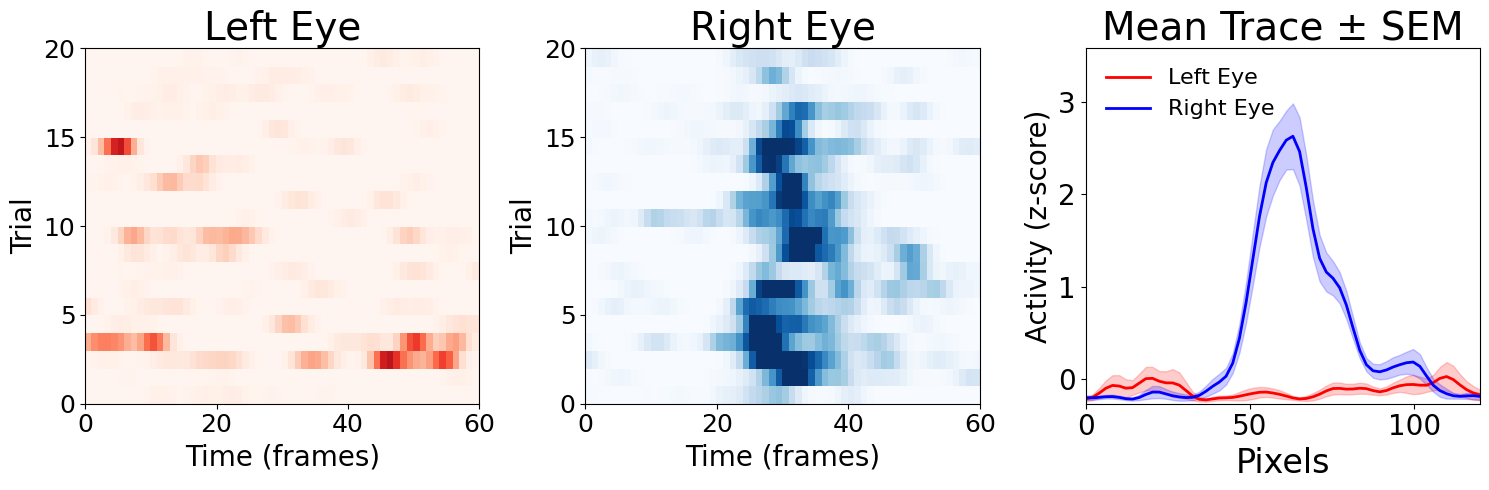

In [9]:
def make_comparison_plot(cell):
    idx = np.where(suite2p_id == cell)[0][0]
    
    vmin = np.percentile(spikes[idx, :], 1)
    vmax = np.percentile(spikes[idx, :], 99)

    left_traces = get_all_traces(cell, eye='left')
    right_traces = get_all_traces(cell, eye='right')

    left_mean, left_std = get_all_traces(cell, eye='left', mean_trace = True)
    right_mean, right_std = get_all_traces(cell, eye='right', mean_trace = True)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Left subplot: heatmap of left responses
    ax1 = axes[0]
    im = ax1.pcolor(left_traces, vmin=vmin, vmax=vmax, cmap='Reds')
    ax1.set_xlabel('Time (frames)', fontsize=20)
    ax1.set_ylabel('Trial', fontsize=20)
    ax1.set_title(f'Left Eye', fontsize=28)
    ax1.tick_params(axis='both', which='major', labelsize=18)
    ax1.figure.axes[-1].yaxis.label.set_size(24)

    # Middle subplot: heatmap of right responses 
    ax1 = axes[1]
    im = ax1.pcolor(right_traces, vmin=vmin, vmax=vmax, cmap='Blues')
    ax1.set_xlabel('Time (frames)', fontsize=20)
    ax1.set_ylabel('Trial', fontsize=20)
    ax1.set_title(f'Right Eye', fontsize=28)
    ax1.tick_params(axis='both', which='major', labelsize=18)
    ax1.figure.axes[-1].yaxis.label.set_size(24)

    # # Right subplot: mean trace with error bars
    ax2 = axes[2]

    start_pos, end_pos = get_screen_positions(eye='left')
    left_range = np.linspace(start_pos, end_pos, np.shape(left_traces)[1])

    start_pos, end_pos = get_screen_positions(eye='right')
    right_range = np.linspace(start_pos, end_pos, np.shape(right_traces)[1])

    ax2.fill_between(left_range, left_mean - left_std, left_mean + left_std, alpha=0.2, color='red')
    ax2.plot(left_range, left_mean, linewidth=2, color='red')

    ax2.fill_between(right_range, right_mean - right_std, right_mean + right_std, alpha=0.2, color='blue')
    ax2.plot(right_range, right_mean, linewidth=2, color='blue')

    ax2.set_xlim(right_range[0], right_range[-1])
    ax2.set_ylim(vmin, vmax)

    ax2.set_xlabel('Pixels', fontsize=24)

    ax2.set_ylabel('Activity (z-score)', fontsize=20)
    ax2.set_title(f'Mean Trace ± SEM', fontsize=28)
    ax2.tick_params(axis='both', which='major', labelsize=20)
    if len(ax2.lines) >= 2:
        ax2.legend(
            handles=[ax2.lines[0], ax2.lines[1]],
            labels=['Left Eye', 'Right Eye'],
            fontsize=16,
            loc='best',
            frameon=False
        )

    plt.tight_layout()

    return fig

fig = make_comparison_plot(cell=159)

In [10]:
results_dir = os.path.join(session_dir, "results")
os.makedirs(results_dir, exist_ok=True)

for cell in suite2p_id:
    fig = make_comparison_plot(cell=cell)
    fig.savefig(os.path.join(results_dir, f"cell_{cell}.png"), dpi=300, bbox_inches="tight")
    plt.close(fig)

# Get Visual Cells from either eye

In [10]:
def compute_reliability(cell, repeat_indices, n_iterations=100, shift_window=None):
    """
    Compute split-half reliability for a cell from a provided set of trial indices.

    This version is adapted for notebook use (no class/self dependency) and works
    directly with the trials you pass (e.g., left-eye trials or right-eye trials).

    Parameters
    ----------
    cell : int
        Cell ID (suite2p_id value).
    repeat_indices : array-like
        Trial indices for the condition of interest.
    n_iterations : int, optional
        Number of split-half iterations (default: 100).
    shift_window : int or None, optional
        Max circular shift (in frames) for null distribution.
        If None, uses half trace length.

    Returns
    -------
    tuple of (corr, corr_shifted)
        corr : ndarray
            Split-half correlation values.
        corr_shifted : ndarray
            Shifted-null split-half correlation values.
    """
    repeat_indices = np.asarray(repeat_indices)

    traces = [get_on_trace(cell, repeat).T for repeat in repeat_indices]
    min_len = min(t.shape[0] for t in traces)
    all_traces = np.array([t[:min_len] for t in traces], dtype=float)

    if all_traces.ndim != 2 or all_traces.shape[0] < 2:
        return np.full(n_iterations, np.nan), np.full(n_iterations, np.nan)

    n_repeats, n_time = all_traces.shape
    n_halves = int(np.ceil(n_repeats / 2))
    max_shift = n_time // 2 if shift_window is None else int(min(abs(shift_window), n_time))

    corr = np.zeros(n_iterations, dtype=float)
    corr_shifted = np.zeros(n_iterations, dtype=float)

    def _safe_corr(a, b):
        c = np.corrcoef(a, b)[0, 1]
        return 0.0 if np.isnan(c) else c

    time_idx = np.arange(n_time)

    for i in range(n_iterations):
        shuffled_idx = np.random.permutation(n_repeats)
        first_idx = shuffled_idx[:n_halves]
        second_idx = shuffled_idx[n_halves:]

        first_mean = all_traces[first_idx].mean(axis=0)
        second_mean = all_traces[second_idx].mean(axis=0)
        corr[i] = _safe_corr(first_mean, second_mean)

        shifts_first = np.random.randint(-max_shift, max_shift + 1, size=len(first_idx))
        shifts_second = np.random.randint(-max_shift, max_shift + 1, size=len(second_idx))

        first_shifted = all_traces[first_idx][
            np.arange(len(first_idx))[:, None],
            (time_idx - shifts_first[:, None]) % n_time,
        ]
        second_shifted = all_traces[second_idx][
            np.arange(len(second_idx))[:, None],
            (time_idx - shifts_second[:, None]) % n_time,
        ]

        corr_shifted[i] = _safe_corr(first_shifted.mean(axis=0), second_shifted.mean(axis=0))

    return corr, corr_shifted


def analyze_cell_reliability(
    cell,
    eye,
    n_iterations=200,
    stimulus_percentile=99,
):
    """
    Analyze reliability for a specific condition (e.g., one eye), optionally against control trials.

    Adapted for the left/right-eye notebook workflow:
    - pass left-eye trials or right-eye trials as `stimulus_trials`
    - optionally pass `control_trials` if you want a control reliability check

    Parameters
    ----------
    cell : int
        Cell ID (suite2p_id value).
    stimulus_trials : array-like
        Trial indices for condition of interest.
    n_iterations : int, optional
        Number of split-half iterations.
    stimulus_percentile : float, optional
        Percentile used for stimulus null threshold.
    control_percentile : float, optional
        Percentile used for control null threshold.

    Returns
    -------
    dict
        Reliabil
        ity metrics for the selected condition.
    """
    eye_repeats = get_eye_repeats(eye)

    corr, corr_shifted = compute_reliability(
        cell=cell,
        repeat_indices=eye_repeats,
        n_iterations=n_iterations,
    )

    mean_corr = np.nanmean(corr)
    reliable = mean_corr > np.nanpercentile(corr_shifted, stimulus_percentile)
    
    return {
        "reliable": bool(reliable),
        "mean_corr": float(mean_corr),
    }

In [11]:
def find_rf_position(cell, eye=None):

    mean_trace = get_all_traces(cell, eye=eye, mean_trace=True)[0]

    # find the receptive field index and its response value for this cell
    rf_idx = int(np.argmax(mean_trace))
    rf_value = float(mean_trace[rf_idx])

    return int(rf_idx), rf_value


In [12]:
all_cells = np.unique(suite2p_id)

start_pos, end_pos = get_screen_positions(eye='right')
right_range = np.linspace(start_pos, end_pos, 60)

start_pos, end_pos = get_screen_positions(eye='left')
left_range = -np.linspace(start_pos, end_pos, 60)

rows = []
for cell in all_cells:

    right_res = analyze_cell_reliability(cell=int(cell), eye="right")
    left_res = analyze_cell_reliability(cell=int(cell), eye="left")

    right_rf, right_val = find_rf_position(cell=int(cell), eye='right')
    left_rf, left_val = find_rf_position(cell=int(cell), eye='left')

    ODI = (np.abs(right_val)-np.abs(left_val))/(np.abs(right_val) + np.abs(left_val))

    rows.append({
        "cell": int(cell),
        "right_reliable": right_res["reliable"],
        "right_mean_corr": right_res["mean_corr"],
        "right_rf": right_rf,
        "right_px": right_range[right_rf],
        "left_reliable": left_res["reliable"],
        "left_mean_corr": left_res["mean_corr"],
        "left_rf": left_rf,
        "left_px": left_range[left_rf],
        "ODI": ODI
    })

cell_stats_df = pd.DataFrame(rows)

In [13]:
cell_stats_df.loc[cell_stats_df["cell"] == 159]

,cell,right_reliable,right_mean_corr,right_rf,right_px,left_reliable,left_mean_corr,left_rf,left_px,ODI
158,159,True,0.962898,31,63.050847,False,-0.020287,5,-109.830508,0.981962


In [14]:
right_reliable_set = set(cell_stats_df.loc[cell_stats_df["right_reliable"], "cell"].tolist())
left_reliable_set = set(cell_stats_df.loc[cell_stats_df["left_reliable"], "cell"].tolist())
all_cells_set = set(cell_stats_df["cell"].tolist())

both_reliable_set = right_reliable_set.intersection(left_reliable_set)
right_only_set = right_reliable_set.difference(both_reliable_set)
left_only_set = left_reliable_set.difference(both_reliable_set)

# Union of mutually exclusive reliable categories (each reliable cell appears exactly once)
either_reliable_set = both_reliable_set.union(right_only_set).union(left_only_set)

# Cells reliable in neither eye
none_reliable_set = all_cells_set.difference(either_reliable_set)

print(f"Cells reliable in BOTH eyes ({len(both_reliable_set)}):")
print(sorted(both_reliable_set))

print(f"\nRight-only reliable cells ({len(right_only_set)}):")
print(sorted(right_only_set))

print(f"\nLeft-only reliable cells ({len(left_only_set)}):")
print(sorted(left_only_set))

print(f"\nNone reliable cells ({len(none_reliable_set)}):")
print(sorted(none_reliable_set))

print(f"\nTotal reliable cells (categorized once) ({len(either_reliable_set)}):")
print(sorted(either_reliable_set))
# End Generation Her

Cells reliable in BOTH eyes (0):
[]

Right-only reliable cells (268):
[4, 8, 12, 15, 16, 17, 20, 21, 25, 28, 35, 42, 43, 44, 46, 47, 51, 56, 57, 59, 64, 65, 66, 73, 77, 78, 82, 83, 86, 91, 95, 105, 106, 108, 111, 112, 114, 116, 117, 119, 120, 126, 127, 128, 130, 137, 139, 140, 141, 142, 143, 144, 145, 149, 152, 153, 156, 157, 159, 160, 161, 168, 169, 171, 175, 178, 179, 181, 182, 188, 191, 193, 195, 209, 211, 212, 213, 215, 219, 220, 223, 226, 231, 233, 234, 238, 239, 242, 243, 247, 248, 249, 250, 251, 252, 255, 256, 257, 258, 260, 261, 262, 264, 265, 266, 267, 268, 270, 272, 274, 275, 276, 277, 279, 286, 287, 288, 289, 294, 298, 299, 301, 303, 308, 309, 310, 312, 313, 314, 319, 320, 321, 322, 324, 325, 327, 330, 332, 334, 335, 336, 341, 342, 343, 346, 354, 355, 359, 369, 371, 376, 380, 381, 382, 383, 386, 387, 389, 390, 391, 393, 396, 397, 398, 402, 403, 408, 410, 412, 413, 414, 416, 418, 421, 422, 426, 427, 439, 440, 442, 446, 451, 453, 459, 460, 463, 465, 469, 474, 477, 478, 479, 48

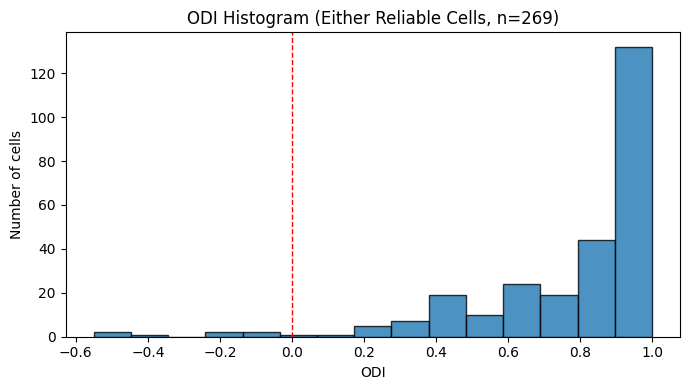

In [15]:
either_reliable_odis = cell_stats_df.loc[
    cell_stats_df["cell"].isin(either_reliable_set), "ODI"
].dropna()

plt.figure(figsize=(7, 4))
plt.hist(either_reliable_odis, bins=15, edgecolor="black", alpha=0.8)
plt.axvline(0, color="red", linestyle="--", linewidth=1)
plt.xlabel("ODI")
plt.ylabel("Number of cells")
plt.title(f"ODI Histogram (Either Reliable Cells, n={len(either_reliable_odis)})")
plt.tight_layout()
plt.show()

Left reliable cells with valid RF values: n=1
Right reliable cells with valid RF values: n=268


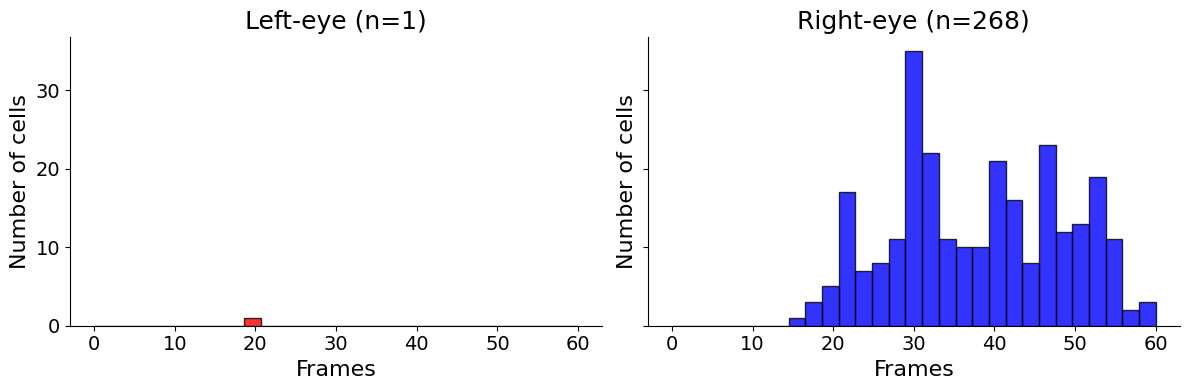

In [18]:
left_reliable_rf = cell_stats_df.loc[
    cell_stats_df["left_reliable"], "left_rf"
].dropna()

right_reliable_rf = cell_stats_df.loc[
    cell_stats_df["right_reliable"], "right_rf"
].dropna()

bins = np.linspace(0, 60, 30)

print(f"Left reliable cells with valid RF values: n={len(left_reliable_rf)}")
print(f"Right reliable cells with valid RF values: n={len(right_reliable_rf)}")

if (len(left_reliable_rf) > 0) or (len(right_reliable_rf) > 0):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

    # Left-eye subplot (left side, red)
    if len(left_reliable_rf) > 0:
        axes[0].hist(left_reliable_rf, bins=bins, color="red", edgecolor="black", alpha=0.8)
    else:
        axes[0].text(0.5, 0.5, "No left reliable RF values", ha="center", va="center", transform=axes[0].transAxes)
    axes[0].set_xlabel("Frames", fontsize=16)
    axes[0].set_ylabel("Number of cells", fontsize=16)
    axes[0].set_title(f"Left-eye (n={len(left_reliable_rf)})", fontsize=18)

    # Right-eye subplot (right side, blue)
    if len(right_reliable_rf) > 0:
        axes[1].hist(right_reliable_rf, bins=bins, color="blue", edgecolor="black", alpha=0.8)
    else:
        axes[1].text(0.5, 0.5, "No right reliable RF values", ha="center", va="center", transform=axes[1].transAxes)
    axes[1].set_xlabel("Frames" , fontsize=16)
    axes[1].set_ylabel("Number of cells", fontsize=16)
    axes[1].set_title(f"Right-eye (n={len(right_reliable_rf)})", fontsize=18)

    for ax in axes:
        ax.tick_params(axis="both", labelsize=14)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("No left or right reliable cells with RF values found.")

Left reliable cells with valid RF values: n=1
Right reliable cells with valid RF values: n=268


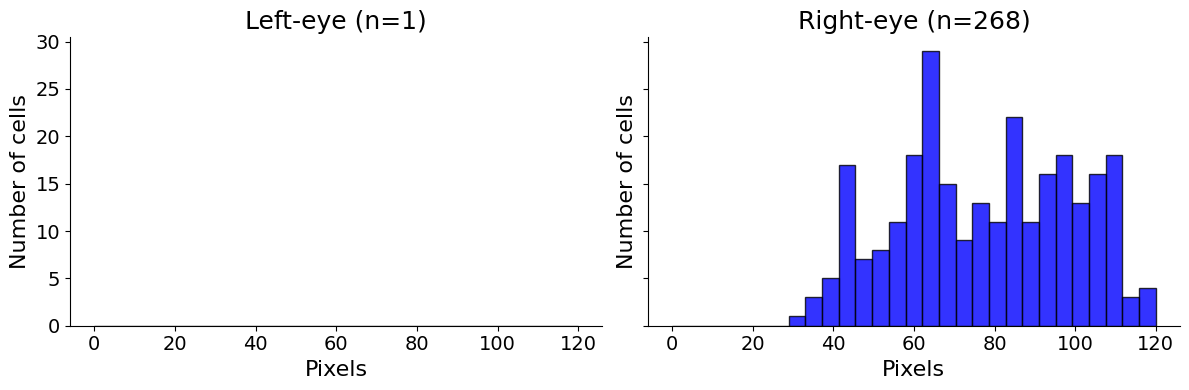

In [17]:
left_reliable_px = cell_stats_df.loc[
    cell_stats_df["left_reliable"], "left_px"
].dropna()

right_reliable_px = cell_stats_df.loc[
    cell_stats_df["right_reliable"], "right_px"
].dropna()

bins = np.linspace(0, 120, 30)

print(f"Left reliable cells with valid RF values: n={len(left_reliable_px)}")
print(f"Right reliable cells with valid RF values: n={len(right_reliable_px)}")

if (len(left_reliable_px) > 0) or (len(right_reliable_px) > 0):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

    # Left-eye subplot (left side, red)
    if len(left_reliable_px) > 0:
        axes[0].hist(left_reliable_px, bins=bins, color="red", edgecolor="black", alpha=0.8)
    else:
        axes[0].text(0.5, 0.5, "No left reliable RF values", ha="center", va="center", transform=axes[0].transAxes)
    axes[0].set_xlabel("Pixels", fontsize=16)
    axes[0].set_ylabel("Number of cells", fontsize=16)
    axes[0].set_title(f"Left-eye (n={len(left_reliable_px)})", fontsize=18)

    # Right-eye subplot (right side, blue)
    if len(right_reliable_px) > 0:
        axes[1].hist(right_reliable_px, bins=bins, color="blue", edgecolor="black", alpha=0.8)
    else:
        axes[1].text(0.5, 0.5, "No right reliable RF values", ha="center", va="center", transform=axes[1].transAxes)
    axes[1].set_xlabel("Pixels" , fontsize=16)
    axes[1].set_ylabel("Number of cells", fontsize=16)
    axes[1].set_title(f"Right-eye (n={len(right_reliable_px)})", fontsize=18)

    for ax in axes:
        ax.tick_params(axis="both", labelsize=14)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("No left or right reliable cells with RF values found.")

In [19]:
both_reliable_df = cell_stats_df.loc[
    cell_stats_df["cell"].isin(both_reliable_set)
    & cell_stats_df["right_reliable"]
    & cell_stats_df["left_reliable"],
    ["cell", "right_px", "left_px"]
].copy()

both_reliable_df["px_diff"] = both_reliable_df["right_px"] - both_reliable_df["left_px"]

print(f"Pixel difference (right - left) for cells reliable in both eyes (n={len(both_reliable_df)}):")
print(both_reliable_df.sort_values("cell").reset_index(drop=True))

if len(both_reliable_df) > 0:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(both_reliable_df["px_diff"], bins=30, edgecolor="black", alpha=0.8)

    most_common_diff = both_reliable_df["px_diff"].value_counts().idxmax()
    ax.axvline(
        most_common_diff,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Most common diff = {most_common_diff:.2f}"
    )

    ax.set_xlabel("Pixel difference (right - left)", fontsize=16)
    ax.set_ylabel("Number of cells", fontsize=16)
    ax.set_title(
        f"Histogram of Pixel Difference (Both Reliable Cells, n={len(both_reliable_df)})",
        fontsize=18
    )
    ax.legend(fontsize=12)
    ax.tick_params(axis="both", labelsize=14)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

Pixel difference (right - left) for cells reliable in both eyes (n=0):
Empty DataFrame
Columns: [cell, right_px, left_px, px_diff]
Index: []


In [20]:
scatter_df = cell_stats_df.loc[
    cell_stats_df["cell"].isin(both_reliable_set)
    & cell_stats_df["right_reliable"]
    & cell_stats_df["left_reliable"],
    ["cell", "right_mean_corr", "left_mean_corr", "right_px", "left_px"]
].copy()

scatter_df["corr_sum"] = scatter_df["right_mean_corr"] + scatter_df["left_mean_corr"]
scatter_df["px_diff"] = scatter_df["right_px"] - scatter_df["left_px"]

print(f"Scatter data (both reliable cells, n={len(scatter_df)}):")
print(scatter_df.sort_values("cell").reset_index(drop=True))

if len(scatter_df) > 0:
    most_common_diff = scatter_df["px_diff"].value_counts().idxmax()

    plt.figure(figsize=(7, 4))
    plt.scatter(
        scatter_df["px_diff"],
        scatter_df["corr_sum"],
        alpha=0.85,
        edgecolor="black"
    )
    plt.axvline(
        most_common_diff,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Most common diff = {most_common_diff:.2f}"
    )
    plt.xlabel("Pixel difference (right - left)")
    plt.ylabel("Right + Left mean correlation")
    plt.title(f"Pixel Difference vs Correlation Sum (n={len(scatter_df)})")
    plt.legend()
    plt.tight_layout()
    plt.show()

Scatter data (both reliable cells, n=0):
Empty DataFrame
Columns: [cell, right_mean_corr, left_mean_corr, right_px, left_px, corr_sum, px_diff]
Index: []


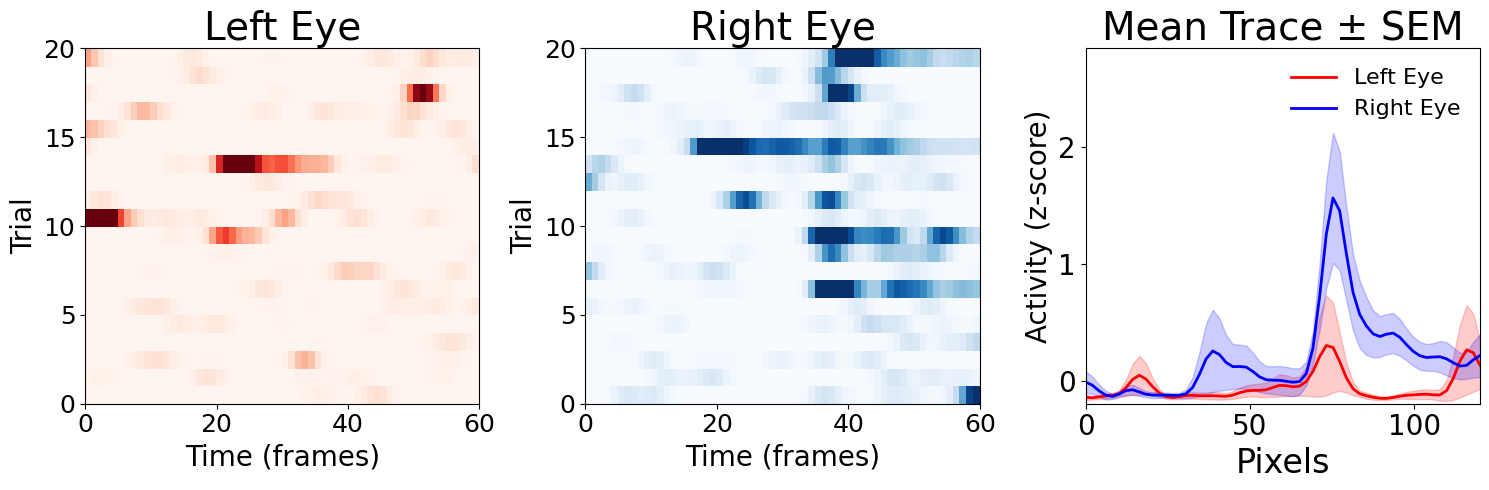

In [37]:
fig = make_comparison_plot(cell=35)

In [21]:
from pathlib import Path
import matplotlib.pyplot as plt

results_dir = os.path.join(session_dir, 'results')

category_map = {
    "both": both_reliable_set,
    "right-only": right_only_set,
    "left-only": left_only_set,
}

# Use the plotting function defined earlier in the notebook
plot_fn = make_comparison_plot
for fn_name in ["plot_cell", "plot_cell_left_right", "plot_left_right_cell"]:
    if fn_name in globals():
        plot_fn = globals()[fn_name]
        break

if plot_fn is None:
    raise NameError("Could not find the plotting function from before (expected one of: plot_cell, plot_cell_left_right, plot_left_right_cell).")

for category, cell_set in category_map.items():
    category_dir = os.path.join(results_dir, category)
    os.makedirs(category_dir, exist_ok=True)

    for cell_id in sorted(cell_set):
        fig = plot_fn(cell_id)  # function from before
        if fig is None:
            fig = plt.gcf()

        fig.savefig(os.path.join(category_dir, f"cell_{cell_id}.png"), dpi=150, bbox_inches="tight")
        plt.close(fig)